# Week 1:

**Goal this week:** confirm the data loads, then summarise samples per woman, group balance, age, and sequencing depth, and check whether samples cluster by donor rather than diagnosis.

In [1]:
# Setup
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.makedirs('data', exist_ok=True); os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)

## 1. Load counts and metadata
Reads the two files straight from the Colab file panel (`/content`). No download step needed. The filenames can have suffixes like `__1_`; they are found by keyword.

In [4]:
counts = pd.read_csv('/content/endometriosis_bulkRNA_count.tsv', sep='\t', index_col=0)
meta   = pd.read_csv('/content/endometriosis_bulkRNA_sample_metadata.tsv', sep='\t')
print('counts:', counts.shape); print('meta:', meta.shape)
display(counts.iloc[:5, :5]); display(meta.head())

counts: (34936, 96)
meta: (96, 11)


,l079,l080,l081,l082,l083
TSPAN6,16,1,0,42,37
TNMD,0,0,0,0,0
DPM1,76,90,1,50,103
SCYL3,1,4,0,16,22
C1orf112,0,3,0,0,2


,donor_ID,sample_ID,library_ID,collection_day,volume_ml,endometriosis,endo_stage,age_range,hormonal_contraceptive,type,cell_type
0,d02,s01,l001,2.0,4.0,False,0,21-25,n,in_vitro,unsorted
1,d02,s01,l009,2.0,4.0,False,0,21-25,n,in_vitro,unsorted
2,d02,s02,l015,3.0,6.5,False,0,21-25,n,in_vitro,unsorted
3,d02,s02,l030,3.0,6.5,False,0,21-25,n,ex_vivo,unsorted
4,d08,s13,l043,3.0,3.5,False,0,21-25,y,in_vitro,unsorted


In [5]:
# Genes should be rows and samples columns (~35,000 x 96). Flip if needed.
if counts.shape[0] < counts.shape[1]:
    counts = counts.T
print('genes x samples:', counts.shape)

# Tell the notebook which metadata columns are which (edit to match meta.columns)
print(list(meta.columns))

genes x samples: (34936, 96)
['donor_ID', 'sample_ID', 'library_ID', 'collection_day', 'volume_ml', 'endometriosis', 'endo_stage', 'age_range', 'hormonal_contraceptive', 'type', 'cell_type']


In [6]:
SAMPLE_COL  = 'library_ID'   # counts columns are library IDs (l001...), NOT sample_ID
DONOR_COL   = 'donor_ID'
DIAG_COL    = 'diagnosis'    # created below from the TRUE/FALSE 'endometriosis' column
AGE_COL     = 'age_range'
STAGE_COL   = 'endo_stage'
CONTRA_COL  = 'hormonal_contraceptive'
CELLTYPE_COL= 'cell_type'    # Cd45p / Cd45m / unsorted
CULTURE_COL = 'type'         # ex_vivo / in_vitro

meta['diagnosis'] = meta['endometriosis'].map({True: 'endometriosis', False: 'control', 'TRUE': 'endometriosis', 'FALSE': 'control'})
assert meta['diagnosis'].notna().all(), 'unexpected values in endometriosis column'
meta = meta.set_index(SAMPLE_COL, drop=False)
meta.index.name = None   # avoids index/column name ambiguity in groupby
common = counts.columns.intersection(meta.index)
print(f'{len(common)} of {counts.shape[1]} count columns match metadata; {len(meta)} metadata rows')
print('Missing from metadata:', set(counts.columns) - set(meta.index))
print('Missing from counts:', set(meta.index) - set(counts.columns))
print('Duplicate IDs:', meta.index.duplicated().sum(), '| Missing values in counts:', int(counts.isna().sum().sum()))
counts = counts[common]; meta = meta.loc[common]

96 of 96 count columns match metadata; 96 metadata rows
Missing from metadata: set()
Missing from counts: set()
Duplicate IDs: 0 | Missing values in counts: 0


## 2. Samples per woman (the core of the research gap)

,donor_ID,diagnosis,n_libraries,n_biological_samples
12,d13,control,17,4
5,d06,endometriosis,17,4
13,d14,control,11,3
17,d18,control,11,6
11,d12,control,6,2
4,d05,endometriosis,5,2
14,d15,control,4,1
1,d02,control,4,2
7,d08,control,3,1
2,d03,endometriosis,3,1


Women per group:
diagnosis
control          11
endometriosis     7
dtype: int64
Libraries (= columns of the counts matrix) per group:
diagnosis
control          66
endometriosis    30
Name: count, dtype: int64
control: top contributor d13 = 17 of 66 libraries (26%)
endometriosis: top contributor d06 = 17 of 30 libraries (57%)


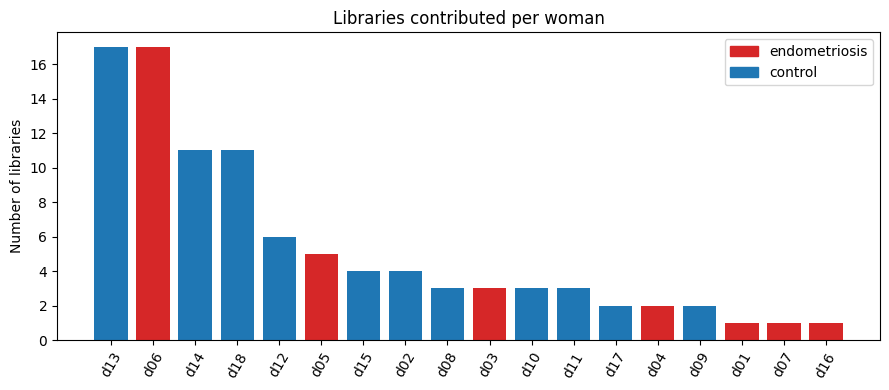

In [7]:
per_donor = (meta.groupby([DONOR_COL, DIAG_COL])
             .agg(n_libraries=('library_ID', 'size'), n_biological_samples=('sample_ID', 'nunique'))
             .reset_index().sort_values('n_libraries', ascending=False))
display(per_donor)
per_donor.to_csv('results/samples_per_donor.csv', index=False)

print('Women per group:'); print(per_donor.groupby(DIAG_COL).size())
print('Libraries (= columns of the counts matrix) per group:'); print(meta[DIAG_COL].value_counts())

# top contributor WITHIN each group (d06 in endometriosis; a control also contributes a lot)
for grp, g in per_donor.groupby(DIAG_COL):
    top = g.sort_values('n_libraries', ascending=False).iloc[0]
    total = g['n_libraries'].sum()
    print(f"{grp}: top contributor {top[DONOR_COL]} = {top['n_libraries']} of {total} libraries ({top['n_libraries']/total:.0%})")

colors = {'endometriosis': 'tab:red', 'control': 'tab:blue'}
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(per_donor[DONOR_COL], per_donor['n_libraries'], color=[colors[g] for g in per_donor[DIAG_COL]])
ax.set_ylabel('Number of libraries'); ax.set_title('Libraries contributed per woman')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in colors.items()])
plt.xticks(rotation=60); plt.tight_layout(); plt.savefig('figures/samples_per_donor.png', dpi=200); plt.show()

## 3. Group balance, sample types, age, other metadata

In [8]:
for col in [CULTURE_COL, CELLTYPE_COL, STAGE_COL, CONTRA_COL]:
    if col:
        print(f'\n--- {col} by diagnosis (libraries) ---')
        display(pd.crosstab(meta[col].fillna('MISSING'), meta[DIAG_COL]))

print('\n--- Sample type x cell type by diagnosis ---')
display(pd.crosstab([meta[CULTURE_COL], meta[CELLTYPE_COL]], meta[DIAG_COL]))

print('\n--- Collection day (NA = not recorded) ---')
display(pd.crosstab(meta['collection_day'].fillna('MISSING'), meta[DIAG_COL]))


--- type by diagnosis (libraries) ---


diagnosis,control,endometriosis
type,,
ex_vivo,45,19
in_vitro,21,11



--- cell_type by diagnosis (libraries) ---


diagnosis,control,endometriosis
cell_type,,
Cd45m,16,10
Cd45p,11,8
unsorted,39,12



--- endo_stage by diagnosis (libraries) ---


diagnosis,control,endometriosis
endo_stage,,
0,66,0
2,0,8
3,0,2
4,0,20


... (2 outputs left out)


--- Sample type x cell type by diagnosis ---


diagnosis           control  endometriosis
type     cell_type                        
ex_vivo  Cd45m            7              6
         Cd45p            9              5
         unsorted        29              8
in_vitro Cd45m            9              4
         Cd45p            2              3
         unsorted        10              4


--- Collection day (NA = not recorded) ---


diagnosis,control,endometriosis
collection_day,,
2.0,33,21
3.0,9,7
MISSING,24,2


In [9]:
# One row per woman. NOTE: use groupby().first(), which skips NaN. drop_duplicates() would keep a
# donor's first row, and some donors have NA age on some rows but not others.
women = meta.groupby(DONOR_COL).agg(diagnosis=(DIAG_COL, 'first'), age_range=(AGE_COL, 'first')).reset_index()
print('--- Age range by diagnosis (women) ---')
display(pd.crosstab(women['age_range'].fillna('MISSING'), women['diagnosis']))

# Age ranges are coarse and not perfectly regular (e.g. 21-25, 25-30), so midpoints are only a rough guide
import re
def midpoint(x):
    nums = [float(v) for v in re.findall(r'\d+', str(x))]
    return np.mean(nums) if nums else np.nan
women['age_mid'] = women['age_range'].map(midpoint)
print(women.groupby('diagnosis')['age_mid'].agg(['count', 'median', 'min', 'max']))
print('Women with missing age:', women.loc[women['age_mid'].isna(), DONOR_COL].tolist())

--- Age range by diagnosis (women) ---


diagnosis,control,endometriosis
age_range,,
21-25,3,2
25-30,1,0
31-35,2,1
35-40,2,1
41-45,1,2
45-50,0,1
MISSING,2,0


               count  median   min   max
diagnosis                               
control            9    33.0  23.0  43.0
endometriosis      7    37.5  23.0  47.5
Women with missing age: ['d12', 'd15']


## 4. Sequencing depth (library size)

,library_size,genes_detected
count,9.600000e+01,96.000000
mean,3.157338e+06,13865.635417
std,2.349969e+06,2821.964949
min,4.605000e+04,3355.000000
25%,1.385010e+06,12754.750000
50%,2.731290e+06,14379.000000
75%,4.267934e+06,15779.000000
max,1.065078e+07,18291.000000


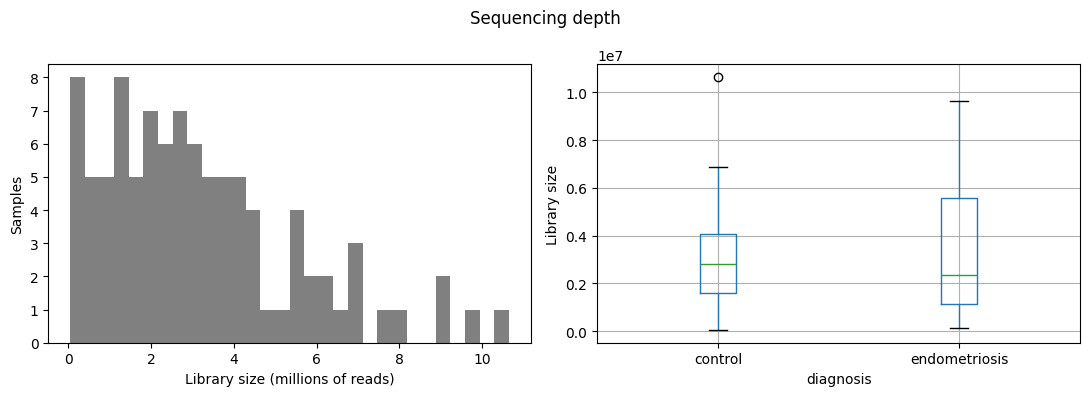

Possible low-depth outliers (<10% of median):


,library_size,genes_detected,donor_ID,diagnosis
l081,74535,5900,d13,control
l085,107931,6616,d15,control
l089,203510,8759,d18,control
l093,46050,3355,d14,control
l096,201193,9000,d13,control
l037,118754,6947,d05,endometriosis
l058,88706,5837,d10,control


In [10]:
libsize = counts.sum(axis=0)
genes_detected = (counts > 0).sum(axis=0)
qc = pd.DataFrame({'library_size': libsize, 'genes_detected': genes_detected}).join(meta[[DONOR_COL, DIAG_COL]])
display(qc.describe())
qc.to_csv('results/sample_qc.csv')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(libsize / 1e6, bins=30, color='gray'); axes[0].set_xlabel('Library size (millions of reads)'); axes[0].set_ylabel('Samples')
qc.boxplot(column='library_size', by=DIAG_COL, ax=axes[1]); axes[1].set_title(''); axes[1].set_ylabel('Library size')
plt.suptitle('Sequencing depth'); plt.tight_layout(); plt.savefig('figures/library_size.png', dpi=200); plt.show()

low = qc[qc['library_size'] < qc['library_size'].median() * 0.1]
print('Possible low-depth outliers (<10% of median):'); display(low)

## 5. PCA: do samples cluster by woman or by disease?
If samples from the same woman sit together, then treating samples as independent is a problem. That is the research gap.

Variance explained: [0.497 0.064 0.042 0.022 0.021]


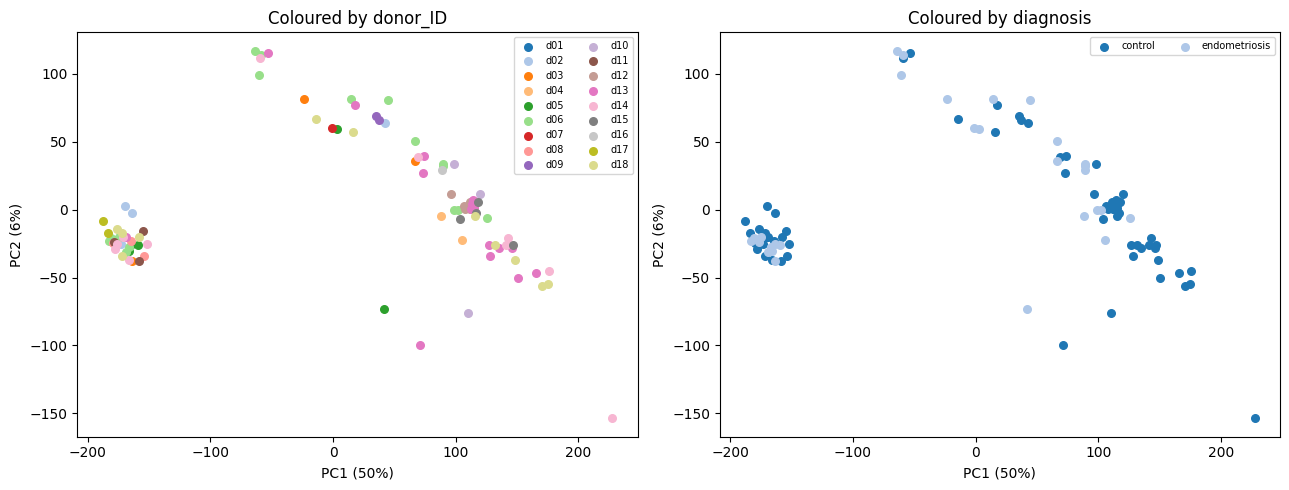

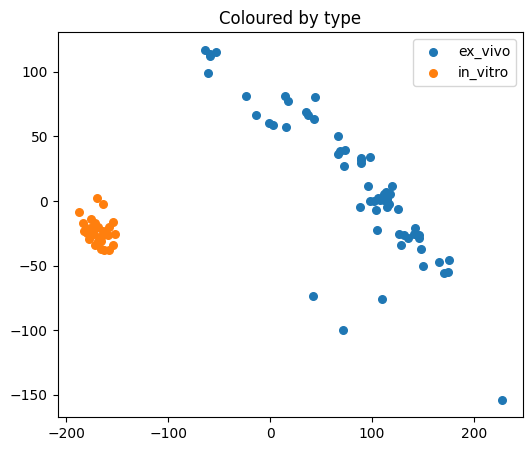

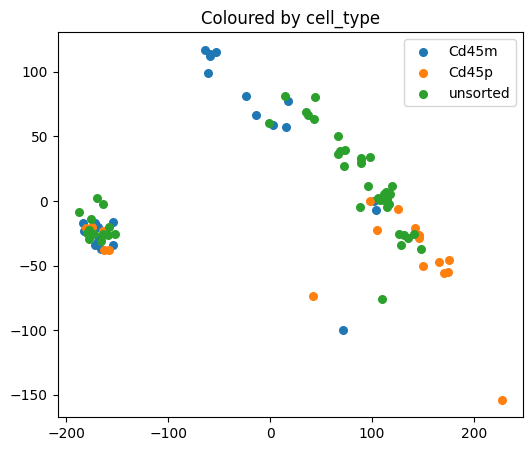

In [11]:
from sklearn.decomposition import PCA
cpm = counts / counts.sum(axis=0) * 1e6
logcpm = np.log2(cpm + 1)
keep = (cpm > 1).sum(axis=1) >= 5          # drop very low-expression genes
X = logcpm[keep].T
X = X - X.mean(axis=0)
pca = PCA(n_components=5).fit(X)
pcs = pd.DataFrame(pca.transform(X), index=X.index, columns=[f'PC{i+1}' for i in range(5)]).join(meta)
print('Variance explained:', np.round(pca.explained_variance_ratio_[:5], 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col in zip(axes, [DONOR_COL, DIAG_COL]):
    cmap = plt.get_cmap('tab20')
    for i, (k, g) in enumerate(pcs.groupby(col)):
        ax.scatter(g['PC1'], g['PC2'], label=k, color=cmap(i % 20), s=30)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
    ax.set_title(f'Coloured by {col}')
    if pcs[col].nunique() <= 20: ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('figures/pca.png', dpi=200); plt.show()

# Extra PCA colouring if available (fresh/cultured, cell type often dominates)
for col in [CULTURE_COL, CELLTYPE_COL]:
    if col:
        fig, ax = plt.subplots(figsize=(6, 5))
        for k, g in pcs.groupby(col): ax.scatter(g['PC1'], g['PC2'], label=k, s=30)
        ax.legend(); ax.set_title(f'Coloured by {col}'); plt.savefig(f'figures/pca_{col}.png', dpi=200); plt.show()

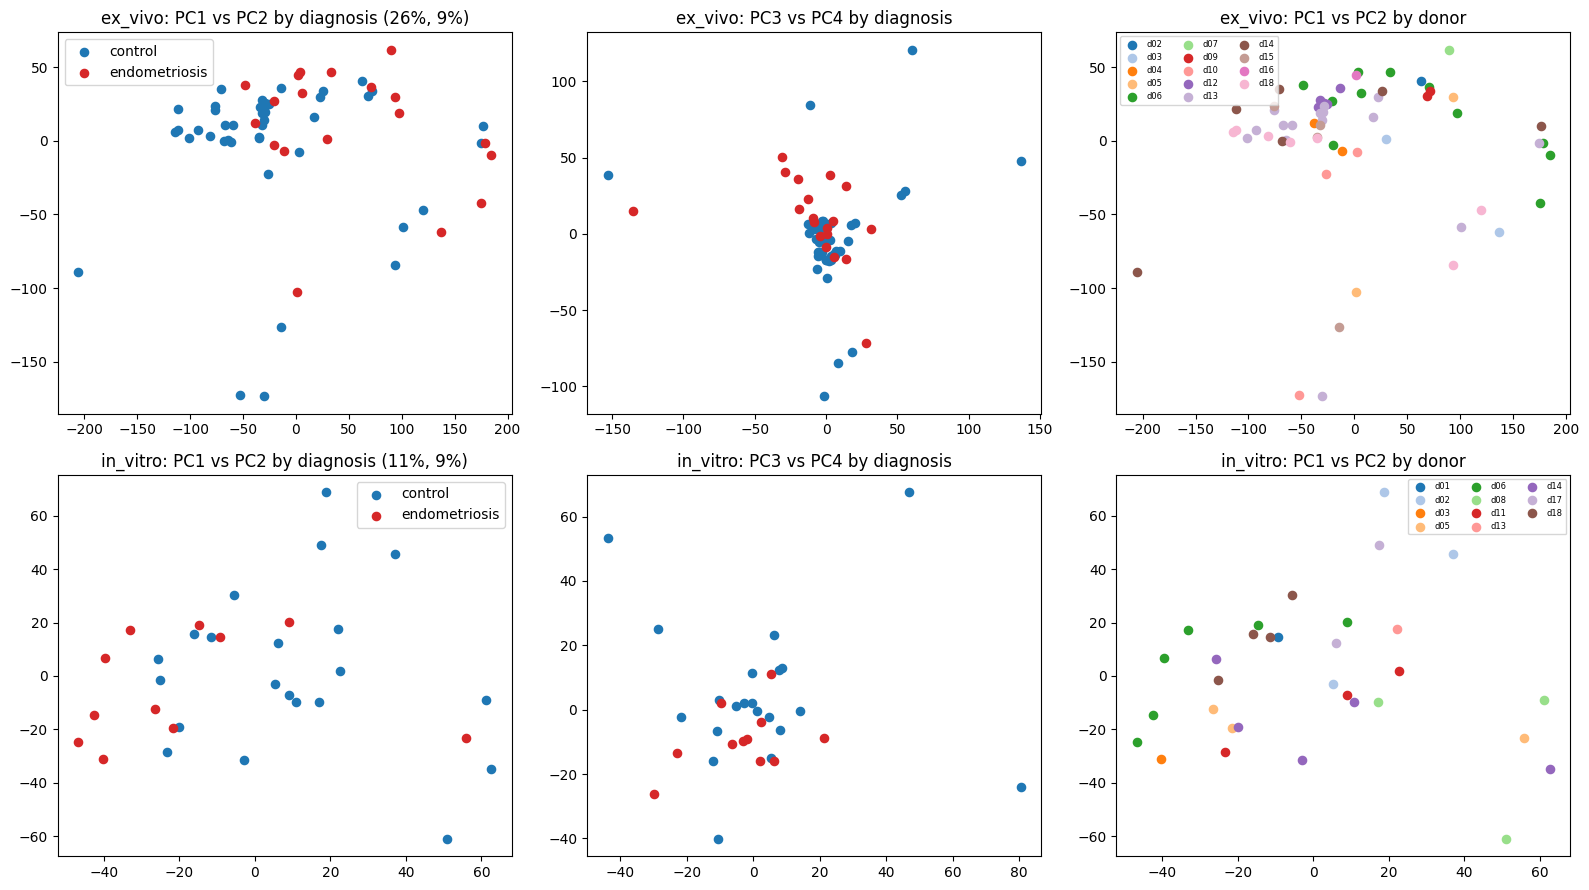

In [12]:
def pca_within(value):
    ids = meta.index[meta['type'] == value]
    sub = logcpm.loc[keep, ids]
    sub = sub.loc[(cpm.loc[keep, ids] > 1).sum(axis=1) >= 3]     # genes expressed in this subset
    X = sub.T - sub.T.mean(axis=0)
    p = PCA(n_components=5).fit(X)
    pc = pd.DataFrame(p.transform(X), index=X.index, columns=[f'PC{i+1}' for i in range(5)]).join(meta)
    return pc, p

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
dcolors = {'endometriosis': 'tab:red', 'control': 'tab:blue'}
for r, value in enumerate(['ex_vivo', 'in_vitro']):
    pc, p = pca_within(value)
    ev = p.explained_variance_ratio_
    for g, d in pc.groupby('diagnosis'):
        axes[r, 0].scatter(d['PC1'], d['PC2'], c=dcolors[g], label=g, s=35)
        axes[r, 1].scatter(d['PC3'], d['PC4'], c=dcolors[g], label=g, s=35)
    cmap = plt.get_cmap('tab20')
    for i, (k, d) in enumerate(pc.groupby(DONOR_COL)):
        axes[r, 2].scatter(d['PC1'], d['PC2'], color=cmap(i % 20), label=k, s=35)
    axes[r, 0].set_title(f'{value}: PC1 vs PC2 by diagnosis ({ev[0]:.0%}, {ev[1]:.0%})')
    axes[r, 1].set_title(f'{value}: PC3 vs PC4 by diagnosis')
    axes[r, 2].set_title(f'{value}: PC1 vs PC2 by donor'); axes[r, 2].legend(fontsize=6, ncol=3)
    axes[r, 0].legend()
plt.tight_layout(); plt.savefig('figures/pca_within_type.png', dpi=200); plt.show()

In [13]:
import re, warnings
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
warnings.filterwarnings('ignore')
os.makedirs('results', exist_ok=True)

LABEL = (meta['diagnosis'] == 'endometriosis').astype(int)      # 1 = endometriosis
print(LABEL.value_counts())

diagnosis
0    66
1    30
Name: count, dtype: int64


In [14]:
# Blood-related genes: hemoglobins, red-cell genes, mitochondrial / MTRNR2L pseudogenes
BLOOD_PAT = re.compile(r'^(HB[ABDEGMQZ]\d*|ALAS2|AHSP|SLC4A1|MT-.*|MTRNR2L\d+)$')
blood_genes = [g for g in counts.index if BLOOD_PAT.match(str(g))]
print(len(blood_genes), 'blood-related genes found:', blood_genes)

def prep(ids, drop_blood):
    # log-CPM, libraries x genes. Unsupervised filter (labels not used): CPM > 1 in at least 10 libraries.
    cp = counts[ids] / counts[ids].sum(axis=0) * 1e6
    lc = np.log2(cp + 1)
    keep_g = (cp > 1).sum(axis=1) >= 10
    if drop_blood: keep_g &= ~cp.index.isin(blood_genes)
    return lc[keep_g].T

def weights(y, donors):
    # each woman counts once in total, and both classes carry equal total weight
    w = 1.0 / donors.map(donors.value_counts())
    for c in (0, 1):
        w[y == c] = w[y == c] * 0.5 / w[y == c].sum()
    return w.values * len(y)

def fit_predict(Xtr, ytr, wtr, Xte, C, n_top=1000):
    # numpy arrays in. Top-variance genes are chosen on the TRAINING libraries only.
    v = np.argsort(Xtr.var(axis=0))[-n_top:]
    mu, sd = Xtr[:, v].mean(axis=0), Xtr[:, v].std(axis=0); sd[sd == 0] = 1
    clf = LogisticRegression(C=C, max_iter=2000).fit((Xtr[:, v] - mu) / sd, ytr, sample_weight=wtr)
    return clf.decision_function((Xte[:, v] - mu) / sd)

def make_folds(X, donors, n_top=1000):
    # leave-one-woman-out folds. Gene selection + standardization never see the labels (or the held-out woman),
    # so they are computed once per fold and reused by the permutation test.
    Xv = X.values; folds = {}
    for d in donors.unique():
        te = (donors == d).values; tr = ~te
        v = np.argsort(Xv[tr].var(axis=0))[-n_top:]
        mu, sd = Xv[tr][:, v].mean(axis=0), Xv[tr][:, v].std(axis=0); sd[sd == 0] = 1
        folds[d] = (tr, te, (Xv[tr][:, v] - mu) / sd, (Xv[te][:, v] - mu) / sd)
    return folds

def logo_scores(folds, y, donors, C):
    # every library of the held-out woman is scored by a model that never saw her
    out = pd.Series(index=y.index, dtype=float)
    for d, (tr, te, Ztr, Zte) in folds.items():
        clf = LogisticRegression(C=C, max_iter=2000)
        clf.fit(Ztr, y.values[tr], sample_weight=weights(y[tr], donors[tr]))
        out.iloc[np.where(te)[0]] = clf.decision_function(Zte)
    return out

def woman_level(scores, y, donors):
    wl = scores.groupby(donors).mean()          # one score per woman
    wy = y.groupby(donors).first()
    return wl, wy

def naive_aucs(X, y, C, n_rep=10, k=5):
    # random library-level split: the same woman can be in train AND test (leaky)
    Xv = X.values; solo = pd.Series(X.index, index=X.index)    # each library its own 'woman' -> class-balanced only
    res = []
    for rep in range(n_rep):
        sc = np.zeros(len(y))
        for tr, te in StratifiedKFold(k, shuffle=True, random_state=rep).split(Xv, y):
            sc[te] = fit_predict(Xv[tr], y.values[tr], weights(y.iloc[tr], solo.iloc[tr]), Xv[te], C)
        res.append(roc_auc_score(y, sc))
    return np.array(res)

def perm_test(folds, y, donors, C, n_perm, seed=0):
    rng = np.random.default_rng(seed)
    wl, wy = woman_level(logo_scores(folds, y, donors, C), y, donors)
    obs = roc_auc_score(wy, wl)
    null = []
    for _ in range(n_perm):
        perm = pd.Series(rng.permutation(wy.values), index=wy.index)     # shuffle labels across WOMEN
        yp = donors.map(perm)
        wlp, wyp = woman_level(logo_scores(folds, yp, donors, C), yp, donors)
        null.append(roc_auc_score(wyp, wlp))
    null = np.array(null)
    return obs, null, (1 + (null >= obs).sum()) / (n_perm + 1), wl, wy

def boot_ci(wl, wy, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed); a = []
    for _ in range(n_boot):
        b = rng.integers(0, len(wl), len(wl))
        if wy.values[b].min() != wy.values[b].max(): a.append(roc_auc_score(wy.values[b], wl.values[b]))
    return np.percentile(a, [2.5, 97.5])
print('ready')

24 blood-related genes found: ['SLC4A1', 'HBQ1', 'HBZ', 'ALAS2', 'AHSP', 'HBA2', 'HBG2', 'HBA1', 'HBM', 'HBE1', 'HBG1', 'HBD', 'MTRNR2L4', 'HBB', 'MTRNR2L8', 'MTRNR2L10', 'MTRNR2L3', 'MTRNR2L1', 'MTRNR2L7', 'MTRNR2L12', 'MTRNR2L11', 'MTRNR2L13', 'MTRNR2L6', 'MTRNR2L2']
ready


In [15]:
C_MAIN = 0.01
ids = meta.index[meta['type'] == 'ex_vivo']
X = prep(ids, drop_blood=True); y = LABEL[ids]; donors = meta.loc[ids, DONOR_COL]
print(f'Fresh libraries: {len(ids)} | women: {donors.nunique()} ({y.groupby(donors).first().sum()} patients, {(1 - y.groupby(donors).first()).sum()} controls) | genes used: {X.shape[1]}')

folds = make_folds(X, donors)
obs, null, p, wl, wy = perm_test(folds, y, donors, C_MAIN, n_perm=500)
ci = boot_ci(wl, wy)
print(f'\nH1 woman-level LOGO AUC = {obs:.3f} | 95% CI (bootstrap over women) {ci[0]:.2f} to {ci[1]:.2f} | permutation p = {p:.3f}')
print('Null AUC distribution: mean %.2f, 95th percentile %.2f' % (null.mean(), np.percentile(null, 95)))
primary = dict(obs=obs, ci=ci, p=p, wl=wl, wy=wy, null=null)

lib_scores = logo_scores(folds, y, donors, C_MAIN)
print(f'Library-level LOGO AUC (pooled libraries, dominated by long-contributing women) = {roc_auc_score(y, lib_scores):.3f}')
print('\nPer-woman held-out scores (higher = more endometriosis-like):')
print(pd.DataFrame({'score': wl.round(2), 'true_endometriosis': wy}).sort_values('score', ascending=False).to_string())

Fresh libraries: 64 | women: 14 (6 patients, 8 controls) | genes used: 15113

H1 woman-level LOGO AUC = 0.458 | 95% CI (bootstrap over women) 0.10 to 0.82 | permutation p = 0.453
Null AUC distribution: mean 0.42, 95th percentile 0.77
Library-level LOGO AUC (pooled libraries, dominated by long-contributing women) = 0.575

Per-woman held-out scores (higher = more endometriosis-like):
          score  true_endometriosis
donor_ID                           
d07        1.33                   1
d09        1.00                   0
d02        0.30                   0
d16       -0.14                   1
d14       -0.47                   0
d06       -0.56                   1
d13       -0.66                   0
d10       -0.70                   0
d18       -0.82                   0
d12       -0.87                   0
d05       -0.88                   1
d04       -1.11                   1
d03       -1.27                   1
d15       -1.83                   0


In [16]:
rows = []
def run(name, ids, drop_blood, n_perm=200):
    X = prep(ids, drop_blood); y = LABEL[ids]; donors = meta.loc[ids, DONOR_COL]
    nat = naive_aucs(X, y, C_MAIN)
    obs, null, p, wl, wy = perm_test(make_folds(X, donors), y, donors, C_MAIN, n_perm)
    lo, hi = boot_ci(wl, wy)
    rows.append(dict(analysis=name, libraries=len(ids), patients=int(wy.sum()), controls=int((1 - wy).sum()),
                     naive_split_AUC=round(nat.mean(), 3), LOGO_woman_AUC=round(obs, 3),
                     CI_low=round(lo, 2), CI_high=round(hi, 2), perm_p=round(p, 3)))
    print(rows[-1])

fresh = meta.index[meta['type'] == 'ex_vivo']
run('Fresh, blood genes REMOVED (primary)', fresh, True)
run('Fresh, blood genes KEPT', fresh, False)
run('Fresh unsorted only, blood removed', meta.index[(meta['type'] == 'ex_vivo') & (meta['cell_type'] == 'unsorted')], True)
run('Cultured, blood removed', meta.index[meta['type'] == 'in_vitro'], True)
res = pd.DataFrame(rows); res.to_csv('results/prediction_summary.csv', index=False)
res

{'analysis': 'Fresh, blood genes REMOVED (primary)', 'libraries': 64, 'patients': 6, 'controls': 8, 'naive_split_AUC': np.float64(0.858), 'LOGO_woman_AUC': np.float64(0.458), 'CI_low': np.float64(0.1), 'CI_high': np.float64(0.82), 'perm_p': np.float64(0.483)}
{'analysis': 'Fresh, blood genes KEPT', 'libraries': 64, 'patients': 6, 'controls': 8, 'naive_split_AUC': np.float64(0.865), 'LOGO_woman_AUC': np.float64(0.5), 'CI_low': np.float64(0.15), 'CI_high': np.float64(0.83), 'perm_p': np.float64(0.438)}
{'analysis': 'Fresh unsorted only, blood removed', 'libraries': 37, 'patients': 5, 'controls': 8, 'naive_split_AUC': np.float64(0.844), 'LOGO_woman_AUC': np.float64(0.475), 'CI_low': np.float64(0.13), 'CI_high': np.float64(0.83), 'perm_p': np.float64(0.393)}
{'analysis': 'Cultured, blood removed', 'libraries': 32, 'patients': 4, 'controls': 7, 'naive_split_AUC': np.float64(0.82), 'LOGO_woman_AUC': np.float64(0.5), 'CI_low': np.float64(0.0), 'CI_high': np.float64(1.0), 'perm_p': np.float64(

,analysis,libraries,patients,controls,naive_split_AUC,LOGO_woman_AUC,CI_low,CI_high,perm_p
0,"Fresh, blood genes REMOVED (primary)",64,6,8,0.858,0.458,0.10,0.82,0.483
1,"Fresh, blood genes KEPT",64,6,8,0.865,0.500,0.15,0.83,0.438
2,"Fresh unsorted only, blood removed",37,5,8,0.844,0.475,0.13,0.83,0.393
3,"Cultured, blood removed",32,4,7,0.820,0.500,0.00,1.00,0.289


In [17]:
# Does age ALONE separate patients from controls? (age ranges -> midpoints; 2 controls have no age)
def midpoint(x):
    nums = [float(v) for v in re.findall(r'\d+', str(x))]
    return np.mean(nums) if nums else np.nan
W = meta.groupby(DONOR_COL).agg(dx=('diagnosis', 'first'), age=('age_range', 'first')).reset_index()
W['age_mid'] = W['age'].map(midpoint); W['y'] = (W['dx'] == 'endometriosis').astype(int)
fresh_women = meta.loc[fresh, DONOR_COL].unique()
for label, sub in [('all women', W), ('women with fresh libraries', W[W[DONOR_COL].isin(fresh_women)])]:
    sub = sub.dropna(subset=['age_mid'])
    print(f"Age-only AUC, {label}: {roc_auc_score(sub['y'], sub['age_mid']):.3f}  (n = {len(sub)} women, {sub['y'].sum()} patients)")

Age-only AUC, all women: 0.651  (n = 16 women, 7 patients)
Age-only AUC, women with fresh libraries: 0.542  (n = 12 women, 6 patients)


In [18]:
# Reported, not used to pick a winner
sens = []
for Cval in [0.001, 0.01, 0.1, 1.0]:
    wl_, wy_ = woman_level(logo_scores(folds, y, donors, Cval), y, donors)
    sens.append(dict(C=Cval, woman_AUC=round(roc_auc_score(wy_, wl_), 3)))
pd.DataFrame(sens)

,C,woman_AUC
0,0.001,0.500
1,0.010,0.458
2,0.100,0.542
3,1.000,0.562


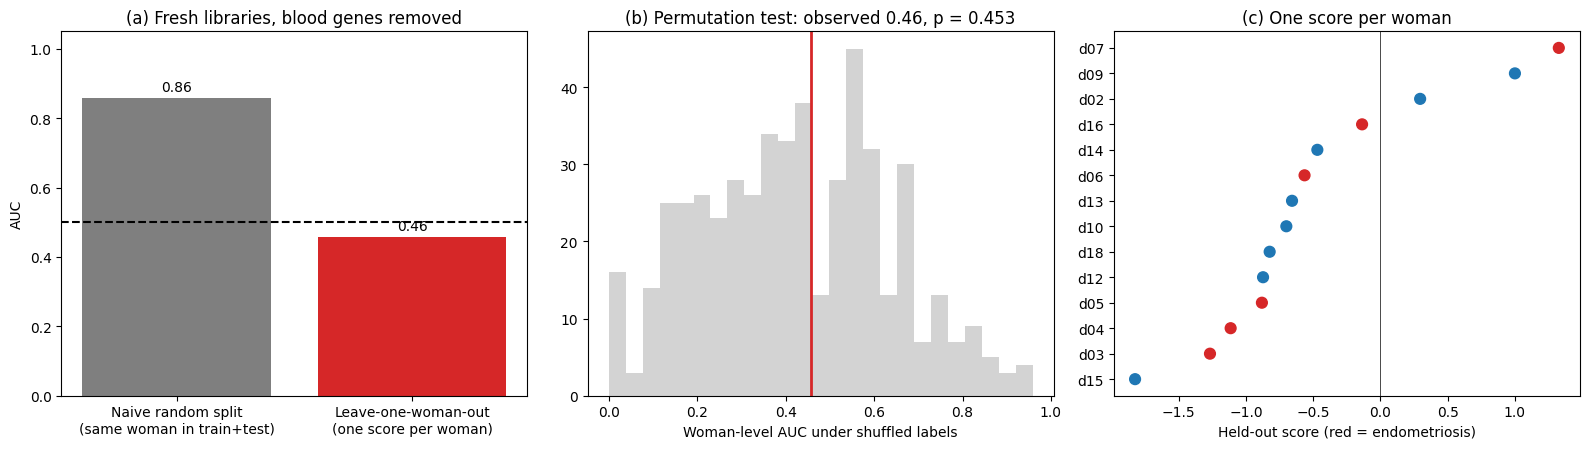

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
# (a) AUC comparison
r = res.iloc[0]
vals = [r['naive_split_AUC'], r['LOGO_woman_AUC']]
ax[0].bar(['Naive random split\n(same woman in train+test)', 'Leave-one-woman-out\n(one score per woman)'], vals, color=['tab:gray', 'tab:red'])
ax[0].axhline(0.5, ls='--', c='k'); ax[0].set_ylim(0, 1.05); ax[0].set_ylabel('AUC'); ax[0].set_title('(a) Fresh libraries, blood genes removed')
for i, v in enumerate(vals): ax[0].text(i, v + 0.02, f'{v:.2f}', ha='center')
# (b) permutation null
ax[1].hist(primary['null'], bins=25, color='lightgray'); ax[1].axvline(primary['obs'], c='tab:red', lw=2)
ax[1].set_xlabel('Woman-level AUC under shuffled labels'); ax[1].set_title(f"(b) Permutation test: observed {primary['obs']:.2f}, p = {primary['p']:.3f}")
# (c) per-woman scores
wl_, wy_ = primary['wl'].sort_values(), primary['wy']
ax[2].scatter(wl_.values, range(len(wl_)), c=['tab:red' if wy_[d] else 'tab:blue' for d in wl_.index], s=60)
ax[2].set_yticks(range(len(wl_))); ax[2].set_yticklabels(wl_.index); ax[2].axvline(0, c='k', lw=0.5)
ax[2].set_xlabel('Held-out score (red = endometriosis)'); ax[2].set_title('(c) One score per woman')
plt.tight_layout(); plt.savefig('figures/week2_prediction.png', dpi=200); plt.show()